# 03 · Kuantum bölgesi ve QM/MM enerjileri
*Makale: Bölüm 2.3, Denklem 6; Şekil 2 turuncu/turkuaz kutular.*

**Kuantum bölgesi = misafir molekül** (makalede de QM bölgesi ligand). Çevredeki her atom (konakçı, su,
iyonlar) QM hesabına bir **nokta yük** olarak giriyor. Buna elektrostatik gömme deniyor:

$$H_\text{QM bölgesi} = H_\text{elektronik, QM} + V_\text{etkileşim, MM}\qquad(\text{makale Denklem 6})$$

Her anlık görüntü $x$ için QM ile MM arasındaki enerji farkını iki parçaya ayırıyoruz:

$$\Delta U_\text{etk}(x) = \big[E_\text{QM}(\text{misafir}\,|\,\text{yükler}) - E_\text{QM}(\text{misafir, vakum})\big] - E^\text{MM}_\text{Coulomb}(\text{misafir–çevre})$$
$$\Delta U_\text{iç}(x) = E_\text{QM}(\text{misafir, vakum}) - E^\text{MM}_\text{iç}(\text{misafir})$$

- $\Delta U_\text{etk}$: çevreyle **etkileşimin** kuantum düzeltmesi (polarizasyon, yük dağılımının doğru tarifi).
  Bağlanmayı doğrudan etkileyen kısım bu.
- $\Delta U_\text{iç}$: misafirin **kendi iç enerjisinin** düzeltmesi (DFT ile GAFF'ın bağ ve açı terimleri farklı).

Misafir–çevre van der Waals terimi her iki seviyede de MM'den geliyor ve sadeleşiyor.
QM seviyesi olarak **PBE/def2-SVP** kullanıyoruz (makale: PBE-D3(BJ)/def2-SVP).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
from qfe import config, store
from qfe.plotting import C, LEG, LEG_TR
import numpy as np, matplotlib.pyplot as plt
# Ön ayar: "test" (hızlı kontrol), "demo" (ekibe gösterim), "standart" (daha güvenilir)
config.set_preset(os.environ.get("QFE_PRESET", "demo"))
print("Aktif ön ayar:", config.preset_name())

Aktif ön ayar: test


In [2]:
from qfe import qmmm
from pyscf import lib
lib.num_threads(os.cpu_count())
pools = {leg: (lambda d: (d["X"], d["B"]))(store.load_npz(f"pool_{leg}.npz")) for leg in ["complex", "solvent"]}
regions = {leg: qmmm.QMRegion(leg) for leg in pools}
for leg, r in regions.items():
    fr = r.frame(pools[leg][0][0], pools[leg][1][0])
    print(f"{leg:8s}: QM atomu={len(fr['qm_xyz'])}, nokta yük={len(fr['pc_q'])}, "
          f"nokta yüklerin toplamı={fr['pc_q'].sum():+.3f} e  (kesme {config.P()['qm_cutoff_A']} Å)")
print("Misafir:", "".join(regions["complex"].guest_symbols()))

complex : QM atomu=16, nokta yük=1251, nokta yüklerin toplamı=-0.000 e  (kesme 14.0 Å)
solvent : QM atomu=16, nokta yük=1203, nokta yüklerin toplamı=+0.000 e  (kesme 14.0 Å)
Misafir: CHHCHHCHHCHCHHOH


### Tek bir QM/MM hesabı: neler hesaplanıyor ve maliyeti nedir?
Aşağıdaki hücre, bir anlık görüntü için gömülü ve vakum DFT hesaplarının süresini ölçüyor. Bu süre,
07. notebook'taki HPC tahmininin temel girdisi.

In [3]:
leg, i = "complex", 0
fr = regions[leg].frame(pools[leg][0][i], pools[leg][1][i])
sym = regions[leg].guest_symbols()
with store.timed("03_tek_DFT"):
    e_emb = qmmm.energy_dft(fr, sym)
e_vac = qmmm.energy_dft(fr, sym, embed=False)
mol = qmmm._mol(fr, sym, config.P()["qm_basis"])
e_mm, e_int, e_coul = regions[leg].mm_qm_part(fr)
H = config.HARTREE_TO_KJ
print(f"E_DFT(gömülü) = {e_emb:.6f} Ha, E_DFT(vakum) = {e_vac:.6f} Ha  ({mol.nao} baz fonksiyonu)")
print(f"QM etkileşim enerjisi (gömülü − vakum) : {(e_emb - e_vac)*H:8.2f} kJ/mol")
print(f"MM Coulomb etkileşimi (sabit yükler)   : {e_coul:8.2f} kJ/mol")
print(f"→ ΔU_etk = {(e_emb - e_vac)*H - e_coul:6.2f} kJ/mol  (çoğunlukla polarizasyon: sabit MM yükleri polarize olamaz)")
store.save_json("results.json", {"qm_nbasis": int(mol.nao), "qm_natoms": len(fr["qm_xyz"]),
                                 "n_threads": os.cpu_count()})

[süre] 03_tek_DFT: 16.0 s


E_DFT(gömülü) = -271.212450 Ha, E_DFT(vakum) = -271.188241 Ha  (134 baz fonksiyonu)
QM etkileşim enerjisi (gömülü − vakum) :   -63.56 kJ/mol
MM Coulomb etkileşimi (sabit yükler)   :   -64.04 kJ/mol
→ ΔU_etk =   0.48 kJ/mol  (çoğunlukla polarizasyon: sabit MM yükleri polarize olamaz)


PosixPath('/home/claude/qb/results/test/results.json')

### Birkaç anlık görüntüde iki parçanın dağılımı
Her bacaktan rastgele birkaç yapı hesaplıyoruz. Bu etiketler önbelleğe alınıyor ve 04. notebook'ta
tekrar kullanılıyor, yani boşa gitmiyorlar.

[süre] 03_DFT_ornekleri: 236.1 s


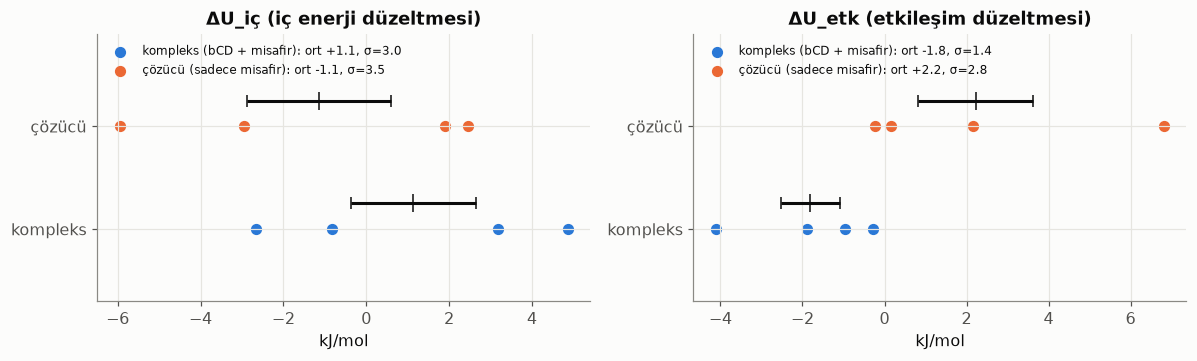

ΔU_iç  ortalama farkı (kompleks − çözücü): +2.28 ± 2.66 kJ/mol
ΔU_etk ortalama farkı (kompleks − çözücü): -4.03 ± 1.82 kJ/mol
Ortalama DFT süresi (gömülü + vakum): 29.5 s / yapı


In [4]:
lab = qmmm.Labeler(regions, pools)
lab.load_dict(store.load_json("labels.json", default={}))
n_probe = max(4, config.P()["al_validation"] // 2)
rng = np.random.default_rng(1)
probe = {leg: rng.choice(len(pools[leg][0]), n_probe, replace=False) for leg in pools}
with store.timed("03_DFT_ornekleri") as rec:
    etk = {leg: np.array([lab.dU_dft(leg, i) for i in probe[leg]]) for leg in pools}
    ic = {leg: np.array([lab.dU_intra(leg, i) for i in probe[leg]]) for leg in pools}
    rec["n"] = 2 * n_probe
store.save_json("labels.json", lab.to_dict())
store.save_json("probe.json", {leg: [int(i) for i in probe[leg]] for leg in probe})

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
off_ic = np.mean(np.concatenate(list(ic.values())))
for ax, data, off, title in [(axs[0], ic, off_ic, "ΔU_iç (iç enerji düzeltmesi)"),
                             (axs[1], etk, 0.0, "ΔU_etk (etkileşim düzeltmesi)")]:
    for k, leg in enumerate(data):
        ax.scatter(data[leg] - off, np.full(len(data[leg]), k), s=40, color=LEG[leg],
                   label=f"{LEG_TR[leg]}: ort {data[leg].mean()-off:+.1f}, σ={data[leg].std():.1f}")
        ax.errorbar(data[leg].mean() - off, k + 0.25, xerr=data[leg].std() / np.sqrt(len(data[leg])),
                    fmt="|", color=C["ink"], capsize=4, ms=12)
    ax.set_yticks([0, 1], ["kompleks", "çözücü"]); ax.set_ylim(-0.7, 1.9)
    ax.set_xlabel("kJ/mol"); ax.set_title(title); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()
se = lambda a: a.std(ddof=1) / np.sqrt(len(a))
print(f"ΔU_iç  ortalama farkı (kompleks − çözücü): {ic['complex'].mean()-ic['solvent'].mean():+.2f} ± "
      f"{np.hypot(se(ic['complex']), se(ic['solvent'])):.2f} kJ/mol")
print(f"ΔU_etk ortalama farkı (kompleks − çözücü): {etk['complex'].mean()-etk['solvent'].mean():+.2f} ± "
      f"{np.hypot(se(etk['complex']), se(etk['solvent'])):.2f} kJ/mol")
print(f"Ortalama DFT süresi (gömülü + vakum): {np.mean(lab.timings['dft']):.1f} s / yapı")

**Bu grafik neden önemli?**

- **$\Delta U_\text{iç}$ çok geniş dağılıyor** (σ ≈ birkaç $kT$), ama **ortalaması iki bacakta aynı**
  (fark hata çubuğu içinde). Molekül aynı ve konformasyonları benzer olduğu için bu kısım bağlanma
  farkında sadeleşiyor. Biz de bu sadeleşmeyi varsayıp ML ve serbest enerji düzeltmesini
  $\Delta U_\text{etk}$ üzerinden yapacağız. (Bu varsayım esnek ya da konformasyonu bağlanınca değişen
  ligandlarda geçerli olmaz. Makale bu yüzden tam enerjiyi kullanıyor ve binlerce QM noktasıyla çalışıyor.)
- **$\Delta U_\text{etk}$ dar dağılıyor ve iki bacakta farklı.** Bağlanmaya giren kuantum düzeltmesi bu.
- Serbest enerji düzeltmesi $\Delta A = -kT \ln\langle e^{-\Delta U/kT}\rangle_\text{MM}$ ile hesaplanıyor.
  Dağılım $kT \approx 2.5$ kJ/mol'den çok genişse ortalama zor yakınsıyor ve çok sayıda QM hesabı gerekiyor.
  Makaledeki ML ve NEQ katmanlarının nedeni bu.